# Modeling 2 — Logistic Regression với 18 biến lịch sử

Baseline theo nhóm recency đã cho một mốc dự báo đơn giản. Câu hỏi tiếp theo là: **18 biến lịch sử có cải thiện xếp hạng và chất lượng xác suất trên validation không?** Notebook dùng đúng các bảng và danh sách biến đã chuẩn bị; không đọc test, không bổ sung feature và không chọn ngưỡng phân loại.

Model đầu tiên này là thử nghiệm POC. Các snapshot của một household lặp lại theo thời gian, do đó không xem từng dòng là hộ độc lập; kết quả validation cũng chưa là bằng chứng tác động kinh doanh.

## 1. Đọc dữ liệu và kiểm tra baseline

Train và validation được đọc qua hợp đồng dữ liệu. Baseline được nối theo `(household_key, snapshot_day)` và kiểm tra nhãn, recency để bảo đảm so sánh cùng quan sát.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss
import joblib

ROOT = Path.cwd()
if ROOT.name == 'research' and ROOT.parent.name == 'notebooks': ROOT = ROOT.parent
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from propensity_v2.prepared_data import load_prepared_split
DATA = ROOT / 'artifacts' / 'data_preparation'
OUT = ROOT / 'artifacts' / 'research'/'modeling_logistic'
train, features = load_prepared_split(DATA, 'train')
validation, vfeatures = load_prepared_split(DATA, 'validation')
assert features == vfeatures and len(features) == 18
assert train.snapshot_day.max() + 7 < validation.snapshot_day.min()
baseline = pd.read_parquet(ROOT / 'artifacts' / 'research'/'baseline_recency' / 'validation_predictions.parquet')
joined = validation.merge(baseline, on=['household_key','snapshot_day'], how='left', validate='one_to_one', suffixes=('','_baseline'))
assert len(joined) == len(validation) and joined.probability.notna().all()
assert joined.target_any_basket.eq(joined.target_any_basket_baseline).all()
assert joined.recency_days.eq(joined.recency_days_baseline).all()
print(f'Train: {len(train):,} household-snapshot; validation: {len(joined):,}; {len(features)} biến.')

Train: 129,834 household-snapshot; validation: 27,480; 18 biến.


## 2. Huấn luyện Logistic Regression

`StandardScaler` được fit bên trong pipeline chỉ trên train. Logistic Regression sử dụng cấu hình mặc định với số vòng lặp đủ lớn; đây là phép so sánh khởi đầu, không phải kết quả đã tối ưu hyperparameter. Các feature có thể tương quan; hệ số không chứng minh tác động nhân quả.

In [2]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=42))
model.fit(train[features], train.target_any_basket)
joined['logistic_probability'] = model.predict_proba(joined[features])[:,1]
assert np.isfinite(joined.logistic_probability).all() and joined.logistic_probability.between(0,1).all()
print('Số vòng lặp:', model.named_steps['logisticregression'].n_iter_[0])

Số vòng lặp: 41


## 3. So sánh validation cùng quy tắc top 10%

Tại mỗi cutoff, chọn `ceil(10% × số household)`; nếu đồng điểm ở ngưỡng, số mua trong các suất còn lại được tính theo kỳ vọng chọn ngẫu nhiên. Lift từng tuần là precision kỳ vọng chia tỷ lệ mua của tuần; lift trong bảng là **trung bình không trọng số qua các cutoff**. Log loss, Brier và ROC-AUC tính trên toàn bộ household-snapshot validation. Các xác suất là đầu ra thô, chưa hiệu chỉnh.

In [3]:
def expected_top_k(y, p, fraction=.10):
    y=np.asarray(y,dtype=float); p=np.asarray(p,dtype=float)
    k=int(np.ceil(fraction*len(y))); threshold=np.partition(p,len(p)-k)[len(p)-k]
    high=p>threshold; tied=p==threshold; slots=k-int(high.sum())
    precision=(y[high].sum()+slots*y[tied].mean())/k
    return {'k':k, 'threshold_ties':int(tied.sum()), 'precision_expected':precision,
            'lift_expected':precision/y.mean() if y.mean() else np.nan}

def compare(frame, name, col):
    y=frame.target_any_basket.to_numpy(); p=frame[col].to_numpy()
    weekly=[{'model':name,'snapshot_day':int(day),**expected_top_k(g.target_any_basket,g[col])}
            for day,g in frame.groupby('snapshot_day',sort=True)]
    return {'model':name,'brier':brier_score_loss(y,p),'log_loss':log_loss(y,p,labels=[0,1]),
            'roc_auc':roc_auc_score(y,p),
            'weekly_lift_mean':np.mean([row['lift_expected'] for row in weekly])}, weekly

base_metrics, base_weekly = compare(joined,'Recency baseline','probability')
log_metrics, log_weekly = compare(joined,'Logistic Regression','logistic_probability')
comparison=pd.DataFrame([base_metrics,log_metrics]).set_index('model')
weekly=pd.DataFrame(base_weekly+log_weekly)
display(comparison)
display(weekly.pivot(index='snapshot_day',columns='model',values='lift_expected'))
print('Chênh lệch Logistic − baseline:'); display((comparison.loc['Logistic Regression']-comparison.loc['Recency baseline']).to_frame('delta'))

Chênh lệch Logistic − baseline:


,brier,log_loss,roc_auc,weekly_lift_mean
model,,,,
Recency baseline,0.199591,0.584073,0.726843,1.313018
Logistic Regression,0.166371,0.501671,0.833017,1.777743


model,Logistic Regression,Recency baseline
snapshot_day,,
551,1.824954,1.329648
558,1.756754,1.324586
565,1.763294,1.310870
572,1.780312,1.306429
579,1.839208,1.320858
586,1.736807,1.311952
593,1.758473,1.298422
600,1.769801,1.281908
607,1.727282,1.308284


,delta
brier,-0.033220
log_loss,-0.082403
roc_auc,0.106174
weekly_lift_mean,0.464726


## 4. Kiểm tra hiệu chỉnh và độ ổn định

Trong biểu đồ reliability, các khoảng xác suất được cố định từ 0 đến 1; ô không có quan sát được bỏ qua. Các chỉ số theo cutoff và nhóm lịch sử giúp kiểm tra xu hướng, nhưng không phải khoảng tin cậy độc lập do household lặp lại. Nhóm lịch sử dưới 180 ngày trong validation rất nhỏ.

,history_group,model,rows,households,brier,auc
0,Dưới 180 ngày,Recency baseline,11,2,0.295019,0.446429
1,Dưới 180 ngày,Logistic Regression,11,2,0.246852,0.357143
2,Từ 180 ngày,Recency baseline,27469,2498,0.199553,0.726920
3,Từ 180 ngày,Logistic Regression,27469,2498,0.166339,0.833082


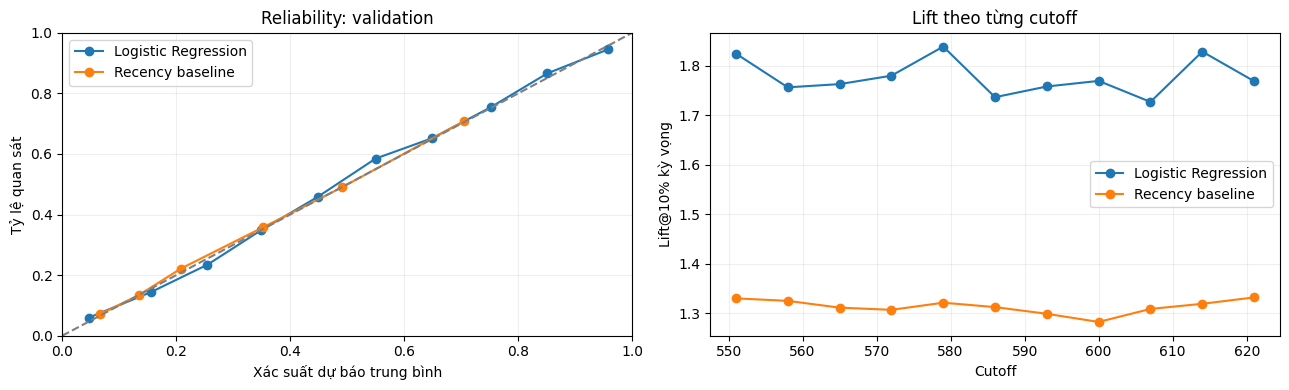

,model,bin,n,mean_prediction,observed
0,Recency baseline,"(-0.001, 0.1]",1992,0.065620,0.070281
1,Recency baseline,"(0.1, 0.2]",879,0.135447,0.135381
2,Recency baseline,"(0.2, 0.3]",1934,0.208393,0.221820
3,Recency baseline,"(0.3, 0.4]",3231,0.351802,0.357474
4,Recency baseline,"(0.4, 0.5]",3606,0.490408,0.489462
5,Recency baseline,"(0.7, 0.8]",15838,0.704739,0.708044
6,Logistic Regression,"(-0.001, 0.1]",1621,0.046915,0.059840
7,Logistic Regression,"(0.1, 0.2]",1998,0.156446,0.144645
8,Logistic Regression,"(0.2, 0.3]",3223,0.254815,0.234564
9,Logistic Regression,"(0.3, 0.4]",3469,0.348559,0.347939


In [4]:
joined['history_group'] = np.where(joined.observed_tenure_days+1 < 180, 'Dưới 180 ngày', 'Từ 180 ngày')
history=[]
for label, g in joined.groupby('history_group',sort=True):
    for name,col in [('Recency baseline','probability'),('Logistic Regression','logistic_probability')]:
        y=g.target_any_basket; p=g[col]
        history.append({'history_group':label,'model':name,'rows':len(g),'households':g.household_key.nunique(),
                        'brier':brier_score_loss(y,p), 'auc':roc_auc_score(y,p) if y.nunique()==2 else np.nan})
history=pd.DataFrame(history); display(history)
calibration=[]
for name,col in [('Recency baseline','probability'),('Logistic Regression','logistic_probability')]:
    frame=joined.assign(bin=pd.cut(joined[col], np.linspace(0,1,11),include_lowest=True))
    tab=frame.groupby('bin',observed=True).agg(mean_prediction=(col,'mean'),observed=( 'target_any_basket','mean'),n=(col,'size')).reset_index()
    tab['model']=name; calibration.append(tab)
calibration=pd.concat(calibration,ignore_index=True)
fig,axes=plt.subplots(1,2,figsize=(13,4))
for name,g in calibration.groupby('model'):
    axes[0].plot(g.mean_prediction,g.observed,marker='o',label=name)
axes[0].plot([0,1],[0,1],'--',color='gray'); axes[0].set(xlabel='Xác suất dự báo trung bình',ylabel='Tỷ lệ quan sát',title='Reliability: validation',xlim=(0,1),ylim=(0,1));axes[0].legend()
for name,g in weekly.groupby('model'):
    axes[1].plot(g.snapshot_day,g.lift_expected,marker='o',label=name)
axes[1].set(xlabel='Cutoff',ylabel='Lift@10% kỳ vọng',title='Lift theo từng cutoff');axes[1].legend()
for ax in axes: ax.grid(alpha=.2)
plt.tight_layout();plt.show()
display(calibration[['model','bin','n','mean_prediction','observed']])

## 5. Lưu kết quả

Lưu pipeline và dự báo validation để tái lập và so sánh LightGBM trong bước tiếp theo. Không đưa `household_key`, cutoff hay cờ bất thường vào danh sách feature; không khẳng định mô hình tốt hơn từ một chỉ số đơn lẻ.

In [5]:
OUT.mkdir(parents=True,exist_ok=True)
joblib.dump({'model':model,'features':features,'target':'target_any_basket'},OUT/'logistic_regression.joblib')
comparison.to_csv(OUT/'validation_comparison.csv',encoding='utf-8-sig')
weekly.to_csv(OUT/'validation_weekly_lift.csv',index=False,encoding='utf-8-sig')
history.to_csv(OUT/'validation_history_groups.csv',index=False,encoding='utf-8-sig')
joined[['household_key','snapshot_day','target_any_basket','probability','logistic_probability']].to_parquet(OUT/'validation_predictions.parquet',index=False)
print('Đã lưu kết quả:',OUT)

Đã lưu kết quả: artifacts\modeling_logistic
